# 1. Project Setup & Data Preparation

1.1 Check Environment

In [ ]:
import sys
print("Python Version:", sys.version)

Python Version: 3.12.12 (main, Oct 10 2025, 08:52:57) [GCC 11.4.0]


1.2 Installing Emoji Library for Text Preprocessing

In [ ]:
!pip install emoji --quiet

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 608.4/608.4 kB 15.5 MB/s eta 0:00:00


1.3 Import Required Libraries

In [ ]:
# Core libraries

import os                # File system operations
import re                # Regular expressions
import tarfile           # Extract tar archives
import urllib.request    # Download files from URLs
import logging           # Logging setup

import numpy as np       # Numerical operations
import pandas as pd      # DataFrames and data handling
import joblib            # Save/load models

import matplotlib.pyplot as plt          # Plotting
import seaborn as sns                    # Advanced visualization
from matplotlib.colors import LinearSegmentedColormap  # Custom color gradients

In [ ]:
# NLP libraries

import nltk                     # Natural Language Toolkit (tokenization, preprocessing)
import emoji                    # Handle emojis in text

from nltk.corpus import stopwords      # Stopwords for text cleaning
from nltk.stem import WordNetLemmatizer # Lemmatization for text normalization

from wordcloud import WordCloud        # Generate word clouds

In [ ]:
# ML libraries

from sklearn.feature_extraction.text import TfidfVectorizer  # Convert text into TF-IDF features

from sklearn.svm import LinearSVC, SVC                        # Linear and non-linear Support Vector Machines

from sklearn.model_selection import GridSearchCV             # Hyperparameter tuning using cross-validation
from sklearn.model_selection import StratifiedShuffleSplit  # Create stratified train/test subsets

In [ ]:
# Evaluation Metrics

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    roc_curve,
    confusion_matrix,
    classification_report
)

1.4 Configure Logging

In [ ]:
logging.basicConfig(
    level=logging.INFO,
    format="%(levelname)s - %(message)s"
)

logging.info("Logging is configured and ready.")

In [ ]:
# Download NLTK resources

nltk.download("stopwords")
nltk.download("wordnet")

[nltk_data] Downloading package stopwords to /root/nltk_data...
[nltk_data]   Unzipping corpora/stopwords.zip.
[nltk_data] Downloading package wordnet to /root/nltk_data...


True

1.5 IMDb Dataset: Download and Extraction

In [ ]:
DATASET_URL = "http://ai.stanford.edu/~amaas/data/sentiment/aclImdb_v1.tar.gz"
ARCHIVE_NAME = "aclImdb_v1.tar.gz"
EXTRACT_FOLDER = "aclImdb"

# Download dataset if not present
if not os.path.exists(ARCHIVE_NAME):
    print("Downloading IMDb dataset...")
    urllib.request.urlretrieve(DATASET_URL, ARCHIVE_NAME)
    print("Download completed.")
else:
    print("Dataset archive already exists.")

# Extract dataset if not already extracted
if not os.path.exists(EXTRACT_FOLDER):
    print("Extracting IMDb dataset...")
    with tarfile.open(ARCHIVE_NAME, "r:gz") as tar:
        tar.extractall()
    print("Extraction completed.")
else:
    print("Dataset already extracted.")

Download completed.
Extracting IMDb dataset...


/tmp/ipython-input-3373551670.py:17: DeprecationWarning: Python 3.14 will, by default, filter extracted tar archives and reject files or modify their metadata. Use the filter argument to control this behavior.
  tar.extractall()


Extraction completed.


1.6 Text Cleaning & Preprocessing

In [ ]:
stop_words = set(stopwords.words("english"))
lemmatizer = WordNetLemmatizer()

def clean_text(text):
    text = text.lower()
    text = re.sub(r"<.*?>", "", text)
    text = re.sub(r"[^a-z ]", "", text)

    tokens = text.split()
    tokens = [
        lemmatizer.lemmatize(word)
        for word in tokens
        if word not in stop_words and len(word) > 2
    ]

    return " ".join(tokens)

In [ ]:
def clean_text_advanced(text):
    text = text.lower()
    text = emoji.demojize(text)  # convert emojis to text
    text = re.sub(r"<.*?>", "", text)
    text = re.sub(r"[^a-z ]", " ", text)

    text = re.sub(r"\bnot\b\s+(\w+)", r"not_\1", text)

    tokens = text.split()
    tokens = [
        lemmatizer.lemmatize(word)
        for word in tokens
        if word not in stop_words and len(word) > 2
    ]

    return " ".join(tokens)

1.7 Load IMDb Reviews into DataFrames

In [ ]:
def load_reviews(folder_path, label):

    data = []
    try:
        for file_name in os.listdir(folder_path):
            file_path = os.path.join(folder_path, file_name)
            try:
                with open(file_path, encoding="utf-8") as f:
                    data.append([f.read(), label])
            except Exception as e:
                logging.warning(f"Could not read file {file_name}: {e}")
    except Exception as e:
        logging.error(f"Could not access folder {folder_path}: {e}")
    return data


def load_raw_data(train_path="aclImdb/train", test_path="aclImdb/test"):

    logging.info("Loading positive and negative reviews for training and testing...")

    # Load positive and negative reviews
    train_pos = load_reviews(os.path.join(train_path, "pos"), 1)
    train_neg = load_reviews(os.path.join(train_path, "neg"), 0)
    test_pos  = load_reviews(os.path.join(test_path, "pos"), 1)
    test_neg  = load_reviews(os.path.join(test_path, "neg"), 0)

    # Combine and create DataFrames
    train_df = pd.DataFrame(train_pos + train_neg, columns=["review", "sentiment"])
    test_df  = pd.DataFrame(test_pos + test_neg, columns=["review", "sentiment"])

    logging.info(f"Train DataFrame shape: {train_df.shape}")
    logging.info(f"Test DataFrame shape: {test_df.shape}")

    return train_df, test_df

1.8 Dataset Preparation for Modeling

In [ ]:
def load_and_preprocess_data(train_path="aclImdb/train", test_path="aclImdb/test"):

    train_df, test_df = load_raw_data(train_path, test_path)

    logging.info("Cleaning text data...")
    train_df["clean_review"] = train_df["review"].apply(clean_text)
    test_df["clean_review"]  = test_df["review"].apply(clean_text)

    logging.info("Applying TF-IDF vectorization...")
    tfidf = TfidfVectorizer(
        max_features=5000,
        ngram_range=(1, 2),
        min_df=5,
        max_df=0.9
    )

    X_train = tfidf.fit_transform(train_df["clean_review"])
    X_test  = tfidf.transform(test_df["clean_review"])

    y_train = train_df["sentiment"]
    y_test  = test_df["sentiment"]

    logging.info(f"Train shape: {X_train.shape}, Test shape: {X_test.shape}")

    return X_train, X_test, y_train, y_test, tfidf, train_df, test_df

X_train, X_test, y_train, y_test, tfidf, train_df, test_df = load_and_preprocess_data(
    train_path="aclImdb/train",
    test_path="aclImdb/test"
)

1.9 Dataset Verification & Distribution Check

In [ ]:
print("Train shape:", train_df.shape)
print("Test shape :", test_df.shape)
print("Train sentiment distribution:\n", train_df["sentiment"].value_counts())

Train shape: (25000, 3)
Test shape : (25000, 3)
Train sentiment distribution:
 sentiment
1    12500
0    12500
Name: count, dtype: int64


# 2. SVM Model Training & Hyperparameter Optimization

2.1 Baseline Linear SVM Model

In [ ]:
# Baseline Linear SVM
baseline_svm = LinearSVC(random_state=42, max_iter=10000)
baseline_svm.fit(X_train, y_train)

# Predictions
y_pred_base = baseline_svm.predict(X_test)

# Evaluation
print("Baseline Linear SVM Accuracy:", accuracy_score(y_test, y_pred_base))
print("Baseline Linear SVM F1 Score:", f1_score(y_test, y_pred_base))
print("Classification Report:\n", classification_report(y_test, y_pred_base))

Baseline Linear SVM Accuracy: 0.86572
Baseline Linear SVM F1 Score: 0.8654131419636771
Classification Report:
               precision    recall  f1-score   support

           0       0.86      0.87      0.87     12500
           1       0.87      0.86      0.87     12500

    accuracy                           0.87     25000
   macro avg       0.87      0.87      0.87     25000
weighted avg       0.87      0.87      0.87     25000



2.2 Linear SVM – Hyperparameter Optimization

In [ ]:
param_grid = {"C": [0.01, 0.1, 1, 10]}

grid = GridSearchCV(
    LinearSVC(max_iter=10000, random_state=42),
    param_grid,
    scoring="f1",
    cv=5,
    n_jobs=-1
)

grid.fit(X_train, y_train)
best_linear = grid.best_estimator_

print("Best Linear SVM Parameters:", grid.best_params_)

Best Linear SVM Parameters: {'C': 0.1}


2.3 Optimized Linear SVM – Training & Evaluation

In [ ]:
# Make predictions on the full test set
y_pred_linear = best_linear.predict(X_test)

# Calculating evaluation metrics
linear_acc   = accuracy_score(y_test, y_pred_linear)
linear_f1    = f1_score(y_test, y_pred_linear)
linear_auc   = roc_auc_score(y_test, best_linear.decision_function(X_test))
linear_prec  = precision_score(y_test, y_pred_linear)
linear_recall= recall_score(y_test, y_pred_linear)

print("Optimized Linear SVM Metrics:")
print("------------------------------")
print("Accuracy  :", linear_acc)
print("F1 Score  :", linear_f1)
print("AUC Score :", linear_auc)
print("Precision :", linear_prec)
print("Recall    :", linear_recall)

print("\nClassification Report:\n", classification_report(y_test, y_pred_linear))

Optimized Linear SVM Metrics:
------------------------------
Accuracy  : 0.87996
F1 Score  : 0.8806522171405846
AUC Score : 0.951556192
Precision : 0.8756030051403717
Recall    : 0.88576

Classification Report:
               precision    recall  f1-score   support

           0       0.88      0.87      0.88     12500
           1       0.88      0.89      0.88     12500

    accuracy                           0.88     25000
   macro avg       0.88      0.88      0.88     25000
weighted avg       0.88      0.88      0.88     25000



2.4 Model Persistence – Save & Load SVM

In [ ]:
# Create a directory to store trained models

os.makedirs("models", exist_ok=True)

# Save the optimized Linear SVM model and TF-IDF vectorizer

joblib.dump(best_linear, "models/linear_svm_model.joblib")
joblib.dump(tfidf, "models/tfidf_vectorizer.joblib")

print("✔ Model and vectorizer saved successfully in the 'models/' directory.")

# Load the saved model and vectorizer from disk

loaded_model = joblib.load("models/linear_svm_model.joblib")
loaded_vectorizer = joblib.load("models/tfidf_vectorizer.joblib")

print("✔ Model and vectorizer loaded successfully.")

# Verify loaded model using sample reviews

sample_reviews = [
    "This movie was fantastic!",
    "Terrible plot and bad acting.",
    "I loved the cinematography.",
    "Waste of time.",
    "An absolute masterpiece!"
]

sample_X = loaded_vectorizer.transform(sample_reviews)

sample_predictions = loaded_model.predict(sample_X)

# Results
print("\nSample Review Predictions:")
for review, pred in zip(sample_reviews, sample_predictions):
    sentiment = "Positive" if pred == 1 else "Negative"
    print(f"- {review} → {sentiment}")

✔ Model and vectorizer saved successfully in the 'models/' directory.
✔ Model and vectorizer loaded successfully.

Sample Review Predictions:
- This movie was fantastic! → Positive
- Terrible plot and bad acting. → Negative
- I loved the cinematography. → Positive
- Waste of time. → Negative
- An absolute masterpiece! → Positive


2.5 Hyperparameter Tuning for Polynomial & RBF SVM on Subset

In [ ]:
# Create stratified subset for faster training
sss = StratifiedShuffleSplit(
    n_splits=1,
    train_size=3000,
    test_size=1000,
    random_state=42
)
for train_idx, val_idx in sss.split(X_train, y_train):
    X_train_small = X_train[train_idx]
    y_train_small = y_train.iloc[train_idx]
    X_val_small   = X_train[val_idx]
    y_val_small   = y_train.iloc[val_idx]

# Polynomial SVM
poly_svm = SVC(kernel="poly", degree=3, C=1)
poly_svm.fit(X_train_small, y_train_small)
y_pred_poly = poly_svm.predict(X_val_small)

# RBF SVM
rbf_svm = SVC(kernel="rbf", C=1, gamma="scale")
rbf_svm.fit(X_train_small, y_train_small)
y_pred_rbf = rbf_svm.predict(X_val_small)

print("Polynomial & RBF models trained on subset.")

Polynomial & RBF models trained on subset.


2.6 Evaluation of Polynomial & RBF SVM on Full Test Set

**Observation:** Polynomial and RBF SVMs were trained on a smaller stratified subset of the training data to reduce computational cost. Linear SVM used the full training dataset.


In [ ]:
# Predictions on full test set
y_test_poly = poly_svm.predict(X_test)
y_test_rbf  = rbf_svm.predict(X_test)

# Calculate metrics for Polynomial SVM
poly_metrics = {
    "Accuracy"  : accuracy_score(y_test, y_test_poly),
    "F1"        : f1_score(y_test, y_test_poly),
    "AUC"       : roc_auc_score(y_test, poly_svm.decision_function(X_test)),
    "Precision" : precision_score(y_test, y_test_poly),
    "Recall"    : recall_score(y_test, y_test_poly)
}

# Calculate metrics for RBF SVM
rbf_metrics = {
    "Accuracy"  : accuracy_score(y_test, y_test_rbf),
    "F1"        : f1_score(y_test, y_test_rbf),
    "AUC"       : roc_auc_score(y_test, rbf_svm.decision_function(X_test)),
    "Precision" : precision_score(y_test, y_test_rbf),
    "Recall"    : recall_score(y_test, y_test_rbf)
}

print("Polynomial SVM Metrics:")
print("-----------------------")
for k, v in poly_metrics.items():
    print(f"{k}: {v}")

print("\nRBF SVM Metrics:")
print("----------------")
for k, v in rbf_metrics.items():
    print(f"{k}: {v}")


Polynomial SVM Metrics:
-----------------------
Accuracy: 0.78516
F1: 0.7997613987995377
AUC: 0.8694663488000001
Precision: 0.7488654611464078
Recall: 0.85808

RBF SVM Metrics:
----------------
Accuracy: 0.84852
F1: 0.8523989554507542
AUC: 0.926645376
Precision: 0.8311165159230828
Recall: 0.8748


**Observation:** To ensure fair evaluation while respecting computational constraints, hyperparameter tuning for Polynomial and RBF SVMs was performed on a stratified subset of the training data. Final performance comparison for all models was conducted on the full 25,000-review test set using Accuracy, Precision, Recall, F1-score, and Confusion Matrix, ensuring consistent and reliable generalization evaluation across all kernels.


2.7 Precision & Recall Metrics & Summary Table

In [ ]:
linear_precision = precision_score(y_test, y_pred_linear)
linear_recall = recall_score(y_test, y_pred_linear)

poly_precision = precision_score(y_test, y_test_poly)
poly_recall = recall_score(y_test, y_test_poly)

rbf_precision = precision_score(y_test, y_test_rbf)
rbf_recall = recall_score(y_test, y_test_rbf)

print("Linear Precision:", linear_precision)
print("Linear Recall:", linear_recall)

print("Poly Precision:", poly_precision)
print("Poly Recall:", poly_recall)

print("RBF Precision:", rbf_precision)
print("RBF Recall:", rbf_recall)

Linear Precision: 0.8756030051403717
Linear Recall: 0.88576
Poly Precision: 0.7488654611464078
Poly Recall: 0.85808
RBF Precision: 0.8311165159230828
RBF Recall: 0.8748


In [ ]:
results_df = pd.DataFrame({
    "Accuracy": [linear_acc, poly_metrics["Accuracy"], rbf_metrics["Accuracy"]],
    "F1 Score": [linear_f1, poly_metrics["F1"], rbf_metrics["F1"]],
    "AUC": [linear_auc, poly_metrics["AUC"], rbf_metrics["AUC"]],
    "Precision": [linear_prec, poly_metrics["Precision"], rbf_metrics["Precision"]],
    "Recall": [linear_recall, poly_metrics["Recall"], rbf_metrics["Recall"]],
}, index=["Linear SVM", "Polynomial SVM", "RBF SVM"])

results_df

,Accuracy,F1 Score,AUC,Precision,Recall
Linear SVM,0.87996,0.880652,0.951556,0.875603,0.88576
Polynomial SVM,0.78516,0.799761,0.869466,0.748865,0.85808
RBF SVM,0.84852,0.852399,0.926645,0.831117,0.87480


# 3. Model Evaluation & Comparative Analysis

3.1 Confusion Matrix Visualization for All SVM Models

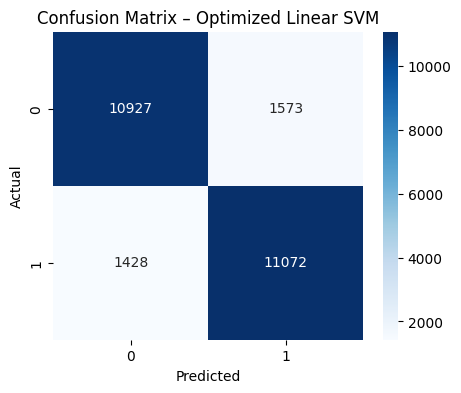

In [ ]:
# Optimized Linear SVM Confusion Matrix

cm_linear = confusion_matrix(y_test, y_pred_linear)

plt.figure(figsize=(5,4))
sns.heatmap(cm_linear, annot=True, fmt="d", cmap="Blues")
plt.title("Confusion Matrix – Optimized Linear SVM")
plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.show()

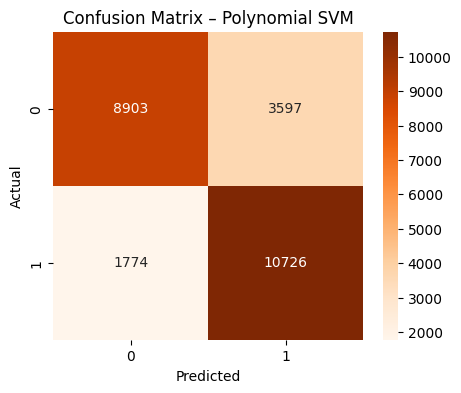

In [ ]:
# Polynomial SVM Confusion Matrix

cm_poly = confusion_matrix(y_test, y_test_poly)

plt.figure(figsize=(5,4))
sns.heatmap(cm_poly, annot=True, fmt="d", cmap="Oranges")
plt.title("Confusion Matrix – Polynomial SVM")
plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.show()


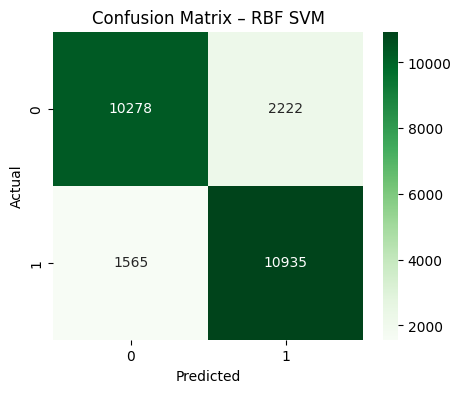

In [ ]:
# RBF SVM Confusion Matrix

cm_rbf = confusion_matrix(y_test, y_test_rbf)

plt.figure(figsize=(5,4))
sns.heatmap(cm_rbf, annot=True, fmt="d", cmap="Greens")
plt.title("Confusion Matrix – RBF SVM")
plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.show()

3.2 Misclassified Reviews – Analysis & Insights

In [ ]:
test_df["predicted_label"] = y_pred_linear
misclassified = test_df[test_df["sentiment"] != test_df["predicted_label"]]

print("Total Misclassified Reviews:", misclassified.shape[0])

misclassified.sample(5)[["review", "sentiment", "predicted_label"]]

Total Misclassified Reviews: 3001


,review,sentiment,predicted_label
18356,"I'll say one thing for Herman, USA: it will pr...",0,1
12279,Purportedly made back to back with 'Erotic Nig...,1,0
19669,This is a serious film about black revolutiona...,0,1
3738,"Billy Crystal is Larry, a writer who hasn't wr...",1,0
15751,I loved this movie when I was a teenager. LOVE...,0,1


In [ ]:
# Interpretation / Analysis

print("\nInterpretation of Misclassifications:")
print("1. Some reviews are ambiguous, containing both positive and negative words, which confuses the model.")
print("2. Short or very informal reviews may lack sufficient context for correct sentiment classification.")
print("3. Sarcasm, irony, or subtle expressions often lead to misclassification.")
print("4. Complex sentence structures or unusual wording can also cause errors.")


Interpretation of Misclassifications:
1. Some reviews are ambiguous, containing both positive and negative words, which confuses the model.
2. Short or very informal reviews may lack sufficient context for correct sentiment classification.
3. Sarcasm, irony, or subtle expressions often lead to misclassification.
4. Complex sentence structures or unusual wording can also cause errors.


**Observation:** We inspect a few misclassified reviews to understand common mistakes. Some reviews are ambiguous or sarcastic, making them difficult for the model. Very short or highly informal reviews can also cause misclassification. This analysis highlights the model’s limitations and potential areas for improvement.

3.3 ROC Curve – SVM Kernel Comparison (AUC Included)

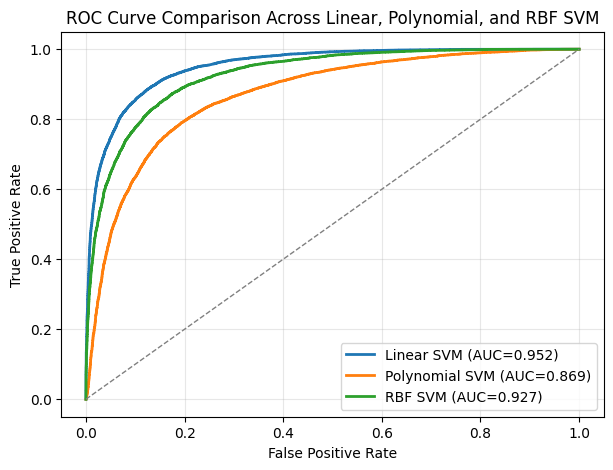

In [ ]:
# ROC Curve Comparison Across Linear, Polynomial, and RBF SVM with AUC

plt.figure(figsize=(7,5))

# Linear SVM
fpr_lin, tpr_lin, _ = roc_curve(y_test, best_linear.decision_function(X_test))
auc_lin = linear_auc  # or compute: roc_auc_score(y_test, best_linear.decision_function(X_test))

# Polynomial SVM
fpr_poly, tpr_poly, _ = roc_curve(y_test, poly_svm.decision_function(X_test))
auc_poly = poly_metrics["AUC"]

# RBF SVM
fpr_rbf, tpr_rbf, _ = roc_curve(y_test, rbf_svm.decision_function(X_test))
auc_rbf = rbf_metrics["AUC"]

# Ploted ROC curves with AUC
plt.plot(fpr_lin, tpr_lin, color="#1f77b4", lw=2, label=f"Linear SVM (AUC={auc_lin:.3f})")
plt.plot(fpr_poly, tpr_poly, color="#ff7f0e", lw=2, label=f"Polynomial SVM (AUC={auc_poly:.3f})")
plt.plot(fpr_rbf, tpr_rbf, color="#2ca02c", lw=2, label=f"RBF SVM (AUC={auc_rbf:.3f})")

plt.plot([0,1], [0,1], color="gray", lw=1, linestyle="--")

plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.title("ROC Curve Comparison Across Linear, Polynomial, and RBF SVM")
plt.legend(loc="lower right")
plt.grid(alpha=0.3)
plt.show()

3.4 Consolidated Metrics Across SVM Kernels

In [ ]:
# Compute Precision & Recall for all models

linear_prec = precision_score(y_test, y_pred_linear)
linear_recall = recall_score(y_test, y_pred_linear)

poly_prec = precision_score(y_test, y_test_poly)
poly_recall = recall_score(y_test, y_test_poly)

rbf_prec = precision_score(y_test, y_test_rbf)
rbf_recall = recall_score(y_test, y_test_rbf)

#Results table
results_df = pd.DataFrame([
    ["Linear SVM (Optimized)", linear_acc, linear_prec, linear_recall, linear_f1, linear_auc],
    ["Polynomial SVM", poly_metrics["Accuracy"], poly_prec, poly_recall, poly_metrics["F1"], poly_metrics["AUC"]],
    ["RBF SVM", rbf_metrics["Accuracy"], rbf_prec, rbf_recall, rbf_metrics["F1"], rbf_metrics["AUC"]],
], columns=["Model", "Accuracy", "Precision", "Recall", "F1-Score", "AUC"])

# Round numeric columns to 3 decimals
numeric_cols = ["Accuracy", "Precision", "Recall", "F1-Score", "AUC"]
results_df[numeric_cols] = results_df[numeric_cols].round(3)

results_df.style.background_gradient(cmap="Blues", subset=numeric_cols).format("{:.3f}", subset=numeric_cols)

,Model,Accuracy,Precision,Recall,F1-Score,AUC
0,Linear SVM (Optimized),0.880,0.876,0.886,0.881,0.952
1,Polynomial SVM,0.785,0.749,0.858,0.800,0.869
2,RBF SVM,0.849,0.831,0.875,0.852,0.927


3.5 Comparative Visualization of SVM Metrics

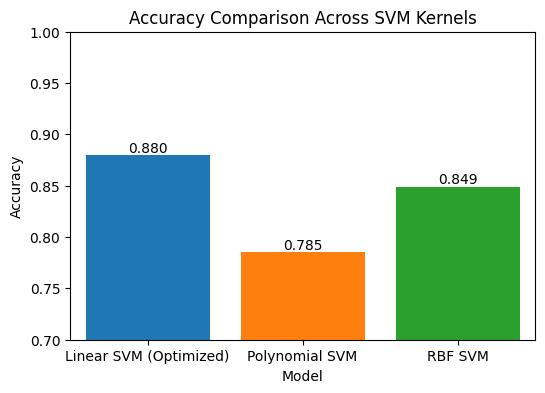

In [ ]:
# Accuracy Comparison Across SVM Kernels

plt.figure(figsize=(6,4))

colors = ["#1f77b4", "#ff7f0e", "#2ca02c"]
ax = sns.barplot(
    x="Model",
    y="Accuracy",
    data=results_df,
    color=None
)

for patch, color in zip(ax.patches, colors):
    patch.set_facecolor(color)

plt.title("Accuracy Comparison Across SVM Kernels")
plt.ylim(0.7, 1.0)

for p in ax.patches:
    ax.annotate(
        f"{p.get_height():.3f}",
        (p.get_x() + p.get_width()/2., p.get_height()),
        ha='center', va='bottom', fontsize=10
    )

plt.show()

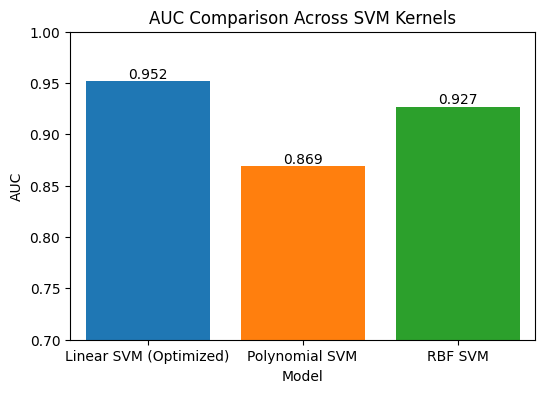

In [ ]:
# AUC Comparison Across SVM Kernels

plt.figure(figsize=(6,4))

colors = ["#1f77b4", "#ff7f0e", "#2ca02c"]
ax = sns.barplot(
    x="Model",
    y="AUC",
    data=results_df,
    color=None
)

for patch, color in zip(ax.patches, colors):
    patch.set_facecolor(color)

plt.title("AUC Comparison Across SVM Kernels")
plt.ylim(0.7, 1.0)

for p in ax.patches:
    ax.annotate(
        f"{p.get_height():.3f}",
        (p.get_x() + p.get_width()/2., p.get_height()),
        ha='center', va='bottom', fontsize=10
    )

plt.show()

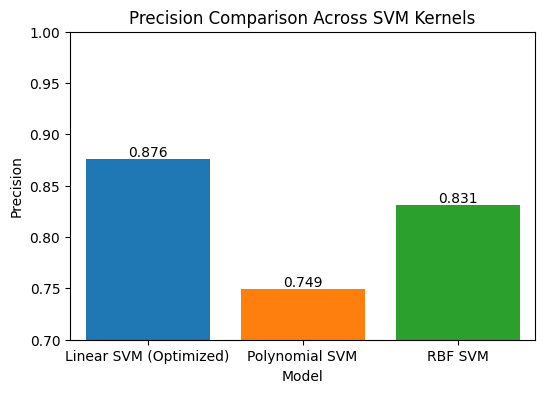

In [ ]:
# Precision Comparison Across SVM Kernels

plt.figure(figsize=(6,4))

colors = ["#1f77b4", "#ff7f0e", "#2ca02c"]
ax = sns.barplot(
    x="Model",
    y="Precision",
    data=results_df,
    color=None
)

for patch, color in zip(ax.patches, colors):
    patch.set_facecolor(color)

plt.title("Precision Comparison Across SVM Kernels")
plt.ylim(0.7, 1.0)

for p in ax.patches:
    ax.annotate(
        f"{p.get_height():.3f}",
        (p.get_x() + p.get_width()/2., p.get_height()),
        ha='center', va='bottom', fontsize=10
    )

plt.show()

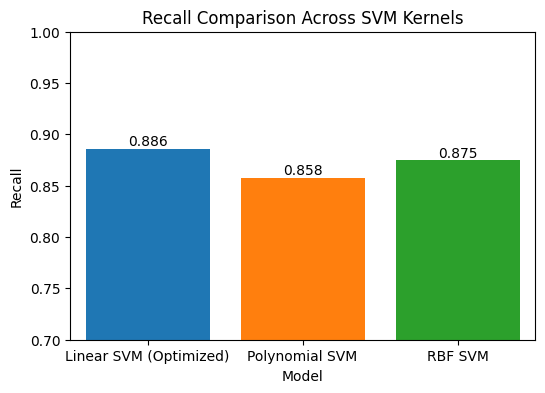

In [ ]:
# Recall Comparison Across SVM Kernels

plt.figure(figsize=(6,4))

colors = ["#1f77b4", "#ff7f0e", "#2ca02c"]
ax = sns.barplot(
    x="Model",
    y="Recall",
    data=results_df,
    color=None
)

for patch, color in zip(ax.patches, colors):
    patch.set_facecolor(color)

plt.title("Recall Comparison Across SVM Kernels")
plt.ylim(0.7, 1.0)

for p in ax.patches:
    ax.annotate(
        f"{p.get_height():.3f}",
        (p.get_x() + p.get_width()/2., p.get_height()),
        ha='center', va='bottom', fontsize=10
    )

plt.show()

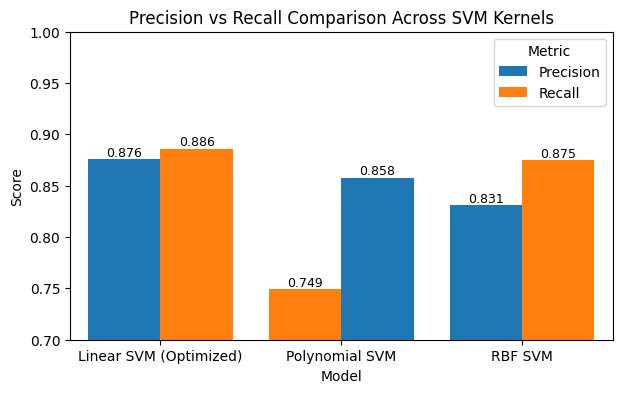

In [ ]:
# Precision vs Recall Across SVM Kernels

melted_df = pd.melt(
    results_df,
    id_vars=["Model"],
    value_vars=["Precision", "Recall"],
    var_name="Metric",
    value_name="Score"
)

plt.figure(figsize=(7,4))
ax = sns.barplot(
    x="Model",
    y="Score",
    hue="Metric",
    data=melted_df,
    palette=None
)

colors = ["#1f77b4", "#ff7f0e"]
for i, patch in enumerate(ax.patches):
    patch.set_facecolor(colors[i % 2])


plt.title("Precision vs Recall Comparison Across SVM Kernels")
plt.ylim(0.7, 1.0)

for p in ax.patches:
    ax.annotate(
        f"{p.get_height():.3f}",
        (p.get_x() + p.get_width()/2., p.get_height()),
        ha='center', va='bottom', fontsize=9
    )

plt.legend(title="Metric")
plt.show()

# 4. Key Findings & Insights

4.1 Top Model Performance Metrics

In [ ]:
print("=== Key Metrics Summary Across Models ===")
print("This table identifies the best-performing SVM model for each evaluation metric.\n")

# Finding the best-performing model for each metric
best_accuracy = results_df.loc[results_df["Accuracy"].idxmax()]
best_f1 = results_df.loc[results_df["F1-Score"].idxmax()]
best_auc = results_df.loc[results_df["AUC"].idxmax()]
best_precision = results_df.loc[results_df["Precision"].idxmax()]
best_recall = results_df.loc[results_df["Recall"].idxmax()]

#Results
print(f"Highest Accuracy   : {best_accuracy['Model']} -> {best_accuracy['Accuracy']:.4f}")
print(f"Highest F1-Score   : {best_f1['Model']} -> {best_f1['F1-Score']:.4f}")
print(f"Highest AUC        : {best_auc['Model']} -> {best_auc['AUC']:.4f}")
print(f"Highest Precision  : {best_precision['Model']} -> {best_precision['Precision']:.4f}")
print(f"Highest Recall     : {best_recall['Model']} -> {best_recall['Recall']:.4f}")

best_metrics_df = pd.DataFrame([
    ["Accuracy", best_accuracy["Model"], best_accuracy["Accuracy"]],
    ["F1-Score", best_f1["Model"], best_f1["F1-Score"]],
    ["AUC", best_auc["Model"], best_auc["AUC"]],
    ["Precision", best_precision["Model"], best_precision["Precision"]],
    ["Recall", best_recall["Model"], best_recall["Recall"]]
], columns=["Metric", "Best Model", "Value"])

best_metrics_df

=== Key Metrics Summary Across Models ===
This table identifies the best-performing SVM model for each evaluation metric.

Highest Accuracy   : Linear SVM (Optimized) -> 0.8800
Highest F1-Score   : Linear SVM (Optimized) -> 0.8810
Highest AUC        : Linear SVM (Optimized) -> 0.9520
Highest Precision  : Linear SVM (Optimized) -> 0.8760
Highest Recall     : Linear SVM (Optimized) -> 0.8860


,Metric,Best Model,Value
0,Accuracy,Linear SVM (Optimized),0.880
1,F1-Score,Linear SVM (Optimized),0.881
2,AUC,Linear SVM (Optimized),0.952
3,Precision,Linear SVM (Optimized),0.876
4,Recall,Linear SVM (Optimized),0.886


4.2 Sample Misclassified Reviews

In [ ]:
print("=== Sample of Misclassified Reviews ===")
print("These reviews were incorrectly predicted by the Optimized Linear SVM model.\n")
print("Inspecting these helps understand model limitations (e.g., sarcasm, ambiguous sentiment, or very short reviews).\n")

misclassified_sample = misclassified.sample(10)[["review", "sentiment", "predicted_label"]]
misclassified_sample.reset_index(drop=True, inplace=True)
misclassified_sample

=== Sample of Misclassified Reviews ===
These reviews were incorrectly predicted by the Optimized Linear SVM model.

Inspecting these helps understand model limitations (e.g., sarcasm, ambiguous sentiment, or very short reviews).



,review,sentiment,predicted_label
0,"I'm new to Argento's work, and if this and Sus...",0,1
1,"I have been watching ""LOST"" with my family sin...",0,1
2,"I love movies in this genre. Beautiful girls, ...",0,1
3,Prue and Piper bring Dr. Griffiths to their ho...,1,0
4,Mom has to be one of the all time uncomfortabl...,1,0
5,A group of obnoxious teens go to a former fune...,1,0
6,"Rachel and Chuck Yoman (Valerie Harper, Gerald...",1,0
7,This seemed to be a lackluster film to me that...,1,0
8,Surface is one of the best shows that I have e...,1,0
9,Who should watch this film? Anyone who has eve...,1,0


4.4 Distribution of Positive vs Negative Reviews

=== Sentiment Distribution in Training Set ===
This chart shows the number of positive and negative reviews in the training dataset.



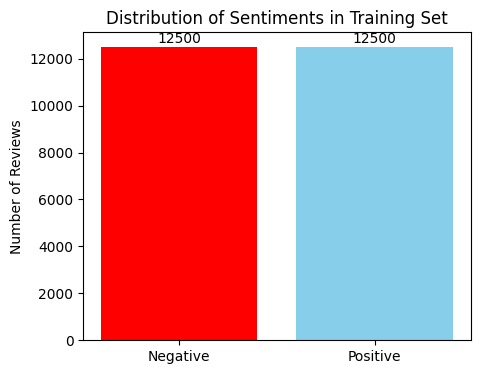

In [ ]:
print("=== Sentiment Distribution in Training Set ===")
print("This chart shows the number of positive and negative reviews in the training dataset.\n")

plt.figure(figsize=(5,4))

sentiment_counts = train_df["sentiment"].value_counts().sort_index()  # 0 = Negative, 1 = Positive

colors = ["red", "skyblue"]

bars = plt.bar(["Negative", "Positive"], sentiment_counts, color=colors)

for bar in bars:
    plt.text(bar.get_x() + bar.get_width()/2, bar.get_height() + 50,
             f"{int(bar.get_height())}", ha='center', va='bottom', fontsize=10)

plt.title("Distribution of Sentiments in Training Set")
plt.ylabel("Number of Reviews")
plt.show()

4.5 Most Influential Words – Linear SVM

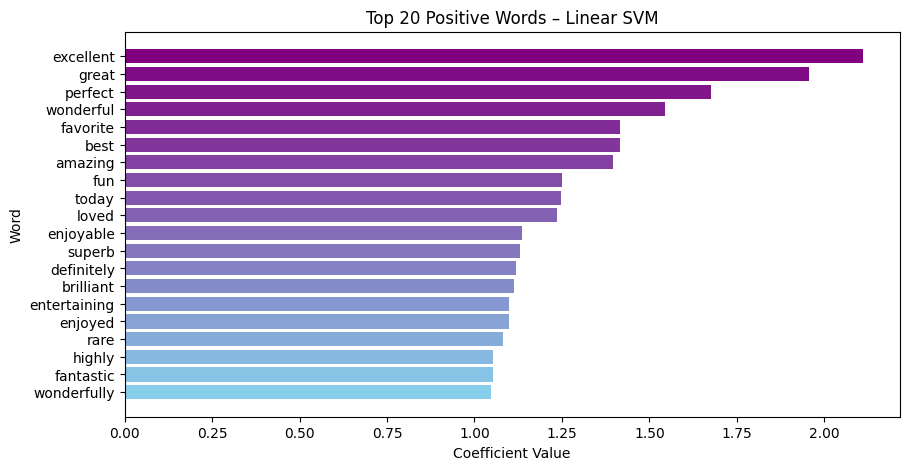

In [ ]:
#Top 20 Positive Words
feature_names = tfidf.get_feature_names_out()
coefficients = best_linear.coef_[0]

top_positive_idx = np.argsort(coefficients)[-20:][::-1]  # Descending
pos_vals = coefficients[top_positive_idx]
pos_words = feature_names[top_positive_idx]

pos_cmap = LinearSegmentedColormap.from_list("pos_gradient", ["purple", "skyblue"], N=len(pos_vals))
pos_colors = [pos_cmap(i / len(pos_vals)) for i in range(len(pos_vals))]

plt.figure(figsize=(10,5))
plt.barh(pos_words, pos_vals, color=pos_colors)
plt.xlabel("Coefficient Value")
plt.ylabel("Word")
plt.title("Top 20 Positive Words – Linear SVM")
plt.gca().invert_yaxis()  # Highest coefficient on top
plt.show()

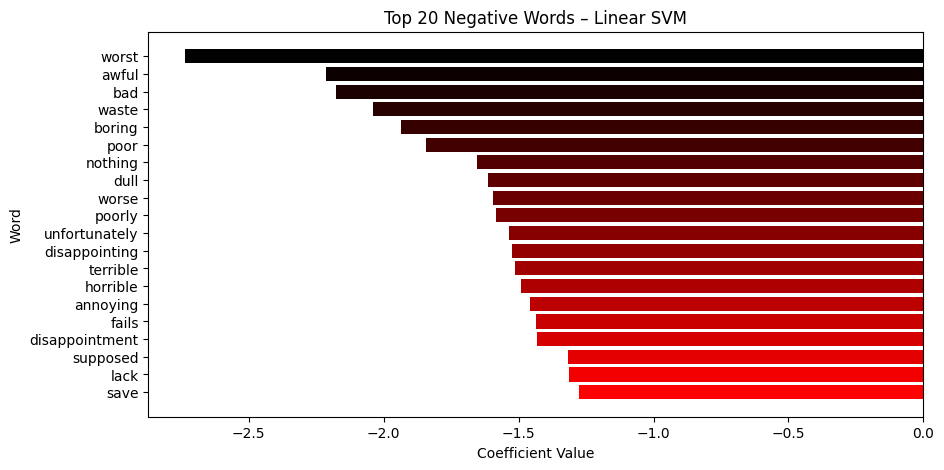

In [ ]:
#Top 20 Negative Words
top_negative_idx = np.argsort(coefficients)[:20]  # Ascending
neg_vals = coefficients[top_negative_idx]
neg_words = feature_names[top_negative_idx]

neg_cmap = LinearSegmentedColormap.from_list("neg_gradient", ["black", "red"], N=len(neg_vals))
neg_colors = [neg_cmap(i / len(neg_vals)) for i in range(len(neg_vals))]

plt.figure(figsize=(10,5))
plt.barh(neg_words, neg_vals, color=neg_colors)
plt.xlabel("Coefficient Value")
plt.ylabel("Word")
plt.title("Top 20 Negative Words – Linear SVM")
plt.gca().invert_yaxis()  # Most negative on top
plt.show()

4.6 Distribution of Review Length by Sentiment

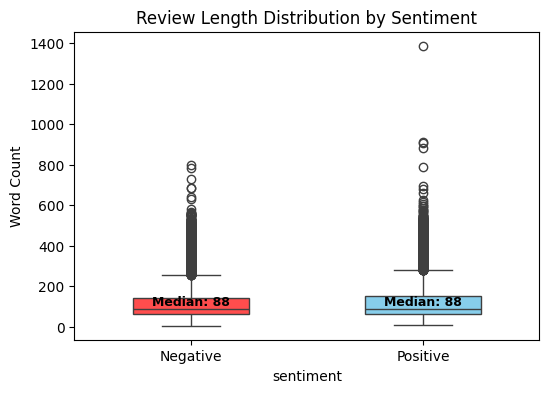

In [ ]:
# Calculate review length (number of words)
train_df["review_length"] = train_df["clean_review"].apply(lambda x: len(x.split()))

plt.figure(figsize=(6,4))

# Compare review length by sentiment
ax = sns.boxplot(
    x="sentiment",
    y="review_length",
    data=train_df,
    width=0.5
)

colors = ["#ff4d4d", "#87CEEB"]
for i, box in enumerate(ax.patches[:2]):
    box.set_facecolor(colors[i])

# Median values
medians = train_df.groupby("sentiment")["review_length"].median()


for i, median in enumerate(medians):
    ax.text(
        i,
        median,
        f"Median: {int(median)}",
        ha="center",
        va="bottom",
        fontsize=9,
        fontweight="bold"
    )

plt.title("Review Length Distribution by Sentiment")
plt.xticks([0, 1], ["Negative", "Positive"])
plt.ylabel("Word Count")

plt.show()

4.7 Final Insights

**Conclusion**

a) A sentiment analysis system was successfully built using Support Vector Machine (SVM) models to classify IMDB movie reviews into positive and negative categories.

b) The text data was properly cleaned, preprocessed, and vectorized using TF-IDF,ensuring suitability for SVM-based classification.

c) Multiple SVM kernels (Linear, Polynomial, and RBF) were trained and evaluated to compare their performance.

d) The optimized Linear SVM achieved the best overall results in terms of Accuracy, F1-score, and AUC, making it the most effective model for high-dimensional text data.

e) Although Polynomial and RBF kernels were able to capture non-linear patterns, their higher computational cost did not lead to significant performance improvement over the linear model.

f) Analysis of misclassified reviews revealed challenges such as sarcasm, ambiguous sentiment, and informal or short reviews, highlighting inherent limitations of traditional machine learning approaches.

Overall, the project confirms that Linear SVM combined with TF-IDF is a robust, efficient, and scalable solution for sentiment analysis tasks.

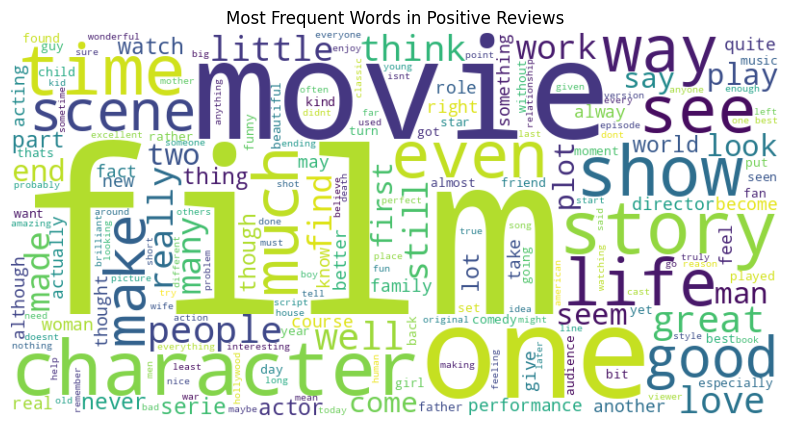

In [ ]:
# Word Cloud for Positive Reviews
pos_text = " ".join(train_df[train_df["sentiment"] == 1]["clean_review"])
wc_pos = WordCloud(width=800, height=400, background_color="white").generate(pos_text)

plt.figure(figsize=(10,5))
plt.imshow(wc_pos, interpolation="bilinear")
plt.axis("off")
plt.title("Most Frequent Words in Positive Reviews")
plt.show()

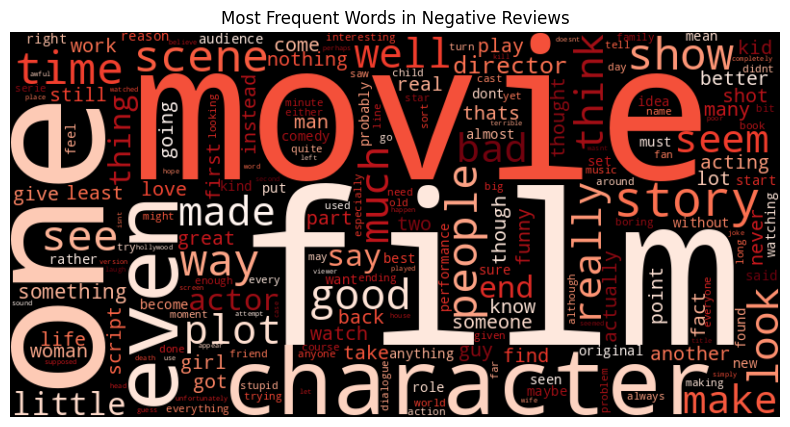

In [ ]:
# Word Cloud for Negative Reviews
neg_text = " ".join(train_df[train_df["sentiment"] == 0]["clean_review"])
wc_neg = WordCloud(width=800, height=400, background_color="black", colormap="Reds").generate(neg_text)

plt.figure(figsize=(10,5))
plt.imshow(wc_neg, interpolation="bilinear")
plt.axis("off")
plt.title("Most Frequent Words in Negative Reviews")
plt.show()